In [32]:
!pip install -q librosa soundfile

In [33]:
import numpy as np
import matplotlib.pyplot as plt
import librosa
import librosa.display
import IPython.display as ipd
from scipy.signal import butter, lfilter

In [36]:
import librosa

path = librosa.example('libri1')      # speech sample
# Aur options: 'trumpet', 'brahms', 'nutcracker', 'choice'

class SimpleClip:
    def __init__(self, path, label):
        self.audio_path = path
        class Tags: pass
        self.tags = Tags()
        self.tags.labels = [label]

clip = SimpleClip(path, 'speech')
clip2 = SimpleClip(librosa.example('trumpet'), 'trumpet')

Clip 1: speech and Clip 2: trumpet

In [38]:
import librosa
import IPython.display as ipd

class SimpleClip:
    def __init__(self, path, label):
        self.audio_path = path
        class Tags: pass
        self.tags = Tags()
        self.tags.labels = [label]

# Clip 1: speech
clip = SimpleClip(librosa.example('libri1'), 'speech')

# Clip 2: trumpet
clip2 = SimpleClip(librosa.example('trumpet'), 'trumpet')

print("Clip 1 (speech):")
ipd.display(ipd.Audio(clip.audio_path))

print("Clip 2 (trumpet):")
ipd.display(ipd.Audio(clip2.audio_path))

Clip 1 (speech):


Clip 2 (trumpet):


Noice Reduction

In [39]:
y, sr = librosa.load(clip.audio_path, sr=None)


In [40]:
# Basic Noise Reduction Filter (High-pass filter to remove low-end rumble)
def butter_highpass_filter(data, cutoff, fs, order=5):
    nyq = 0.5 * fs
    normal_cutoff = cutoff / nyq
    b, a = butter(order, normal_cutoff, btype='high', analog=False)
    y_filtered = lfilter(b, a, data)
    return y_filtered

Applying Filter

In [53]:

y_clean = butter_highpass_filter(y, cutoff=300, fs=sr)

In [42]:
sr

22050

Metadata aur sample values print

In [43]:
print(f"--- Audio Analysis ---")
print(f"Sampling Rate (Hz): {sr} (samples per second)")
print(f"Total Number of Samples: {len(y)}")
print(f"Data Type: {y.dtype}\n")

print("--- Raw Sample Array (Snapshot) ---")
print(y)

print("\n--- Print First 20 Actual Sample Values ---")
for i, val in enumerate(y[:20]):
    print(f"Sample {i:02d}: {val: .6f}")

--- Audio Analysis ---
Sampling Rate (Hz): 22050 (samples per second)
Total Number of Samples: 327222
Data Type: float32

--- Raw Sample Array (Snapshot) ---
[0.00037424 0.00036333 0.00024905 ... 0.00101743 0.0023917  0.00200722]

--- Print First 20 Actual Sample Values ---
Sample 00:  0.000374
Sample 01:  0.000363
Sample 02:  0.000249
Sample 03:  0.000201
Sample 04:  0.000138
Sample 05:  0.000145
Sample 06:  0.000165
Sample 07:  0.000145
Sample 08:  0.000081
Sample 09:  0.000145
Sample 10:  0.000161
Sample 11:  0.000084
Sample 12:  0.000106
Sample 13:  0.000215
Sample 14:  0.000261
Sample 15:  0.000209
Sample 16:  0.000218
Sample 17:  0.000217
Sample 18:  0.000252
Sample 19:  0.000253


Original vs Noise Reduced waveform

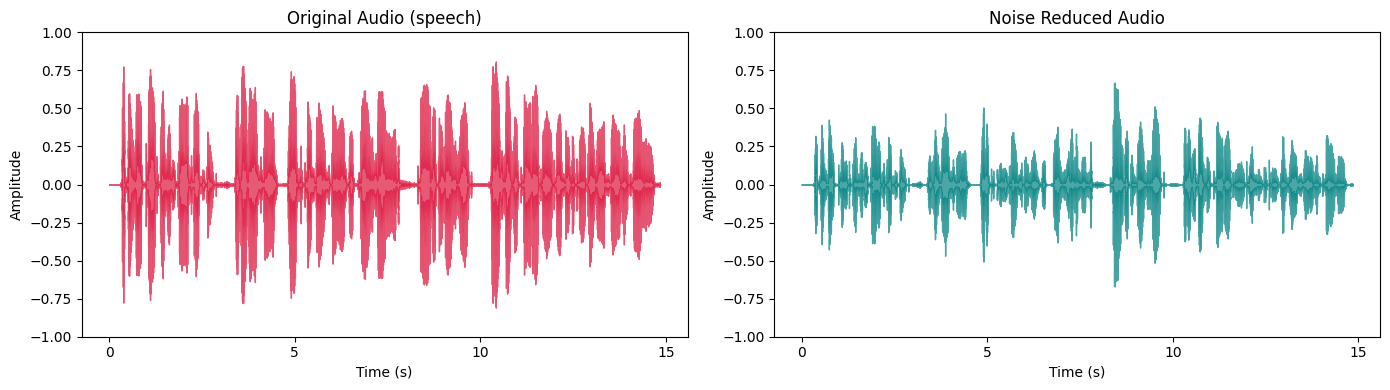

In [44]:
plt.figure(figsize=(14, 4))

# Plot Original Audio
plt.subplot(1, 2, 1)
librosa.display.waveshow(y, sr=sr, color='crimson', alpha=0.7)
plt.title(f'Original Audio ({clip.tags.labels[0]})')
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.ylim(-1, 1)

# Plot Cleaned Audio
plt.subplot(1, 2, 2)
librosa.display.waveshow(y_clean, sr=sr, color='teal', alpha=0.7)
plt.title('Noise Reduced Audio')
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.ylim(-1, 1)

plt.tight_layout()
plt.show()

Plot the Comparison

In [45]:
print("Original Audio:")
ipd.display(ipd.Audio(y, rate=sr))

print("Cleaned Audio:")
ipd.display(ipd.Audio(y_clean, rate=sr))


Original Audio:


Cleaned Audio:


 MFCC on Clip 1


For Original Audio


In [54]:
# n_mels=128 audio classification standard
mel_spect = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=128)
mel_spect_db = librosa.power_to_db(mel_spect, ref=np.max)   # convert to db unit

# 40 MFCC coefficients is standard practice in environmental sound datasets
mfccs = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=40)
mfccs

array([[-565.9195   , -564.28815  , -562.8431   , ..., -437.97177  ,
        -426.48358  , -434.66782  ],
       [  10.304619 ,   12.508709 ,   14.130636 , ...,   89.98184  ,
          88.43013  ,   90.12026  ],
       [   9.748489 ,   11.672071 ,   12.139029 , ...,  -10.730866 ,
         -10.773369 ,   -5.22457  ],
       ...,
       [  -1.5704864,   -2.0978153,   -3.0435863, ...,   -2.5859597,
          -4.400791 ,   -4.668358 ],
       [  -1.9920218,   -2.682422 ,   -3.1783807, ...,   -4.0454345,
           1.4878969,    3.63626  ],
       [  -2.146381 ,   -2.8828554,   -2.8759928, ...,    1.6754   ,
           3.1740217,    2.818036 ]], dtype=float32)

Both features side-by-side plot

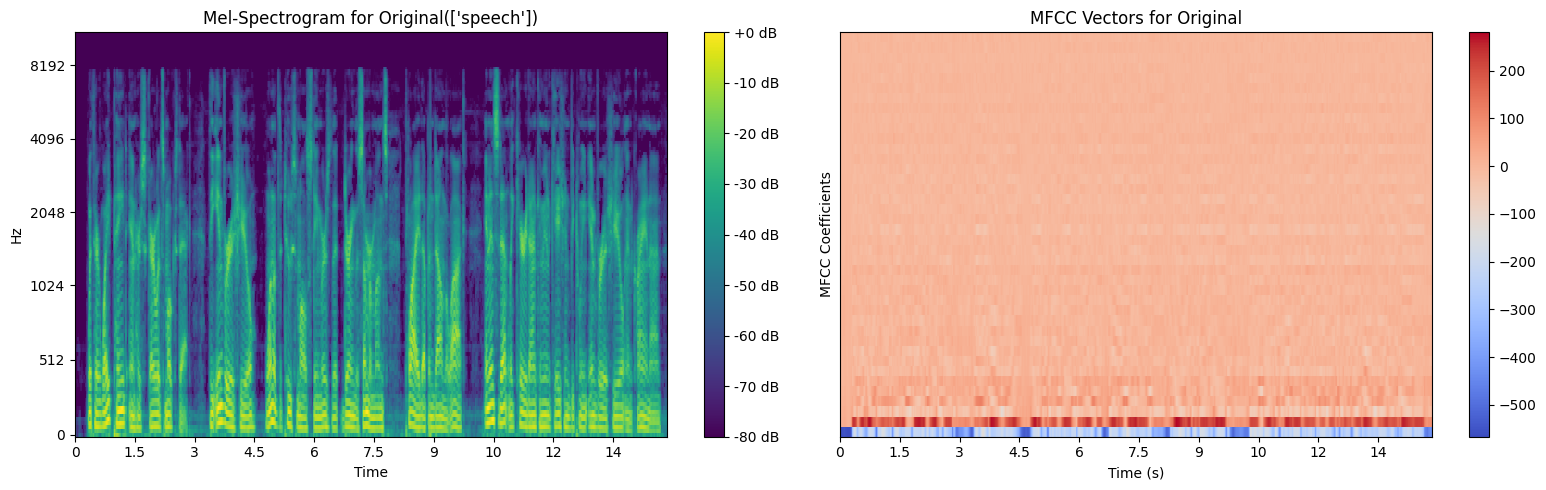

In [48]:
plt.figure(figsize=(16, 5))

# Subplot 1: Mel-Spectrogram
plt.subplot(1, 2, 1)
librosa.display.specshow(mel_spect_db, sr=sr, x_axis='time', y_axis='mel', cmap='viridis')
plt.colorbar(format='%+2.0f dB')
plt.title(f'Mel-Spectrogram for Original({clip.tags.labels})')

# Subplot 2: MFCC
plt.subplot(1, 2, 2)
librosa.display.specshow(mfccs, sr=sr, x_axis='time', cmap='coolwarm')
plt.colorbar()
plt.title('MFCC Vectors for Original')
plt.xlabel('Time (s)')
plt.ylabel('MFCC Coefficients')

plt.tight_layout()
plt.show()

Feature shapes

In [49]:
print(f"Original Waveform shape: {y.shape}")
print(f"Mel-Spectrogram matrix shape: {mel_spect_db.shape} (Mels, Frames)")
print(f"MFCC matrix shape: {mfccs.shape} (Coefficients, Frames)")

Original Waveform shape: (327222,)
Mel-Spectrogram matrix shape: (128, 640) (Mels, Frames)
MFCC matrix shape: (40, 640) (Coefficients, Frames)


For Noise Reduced Audio

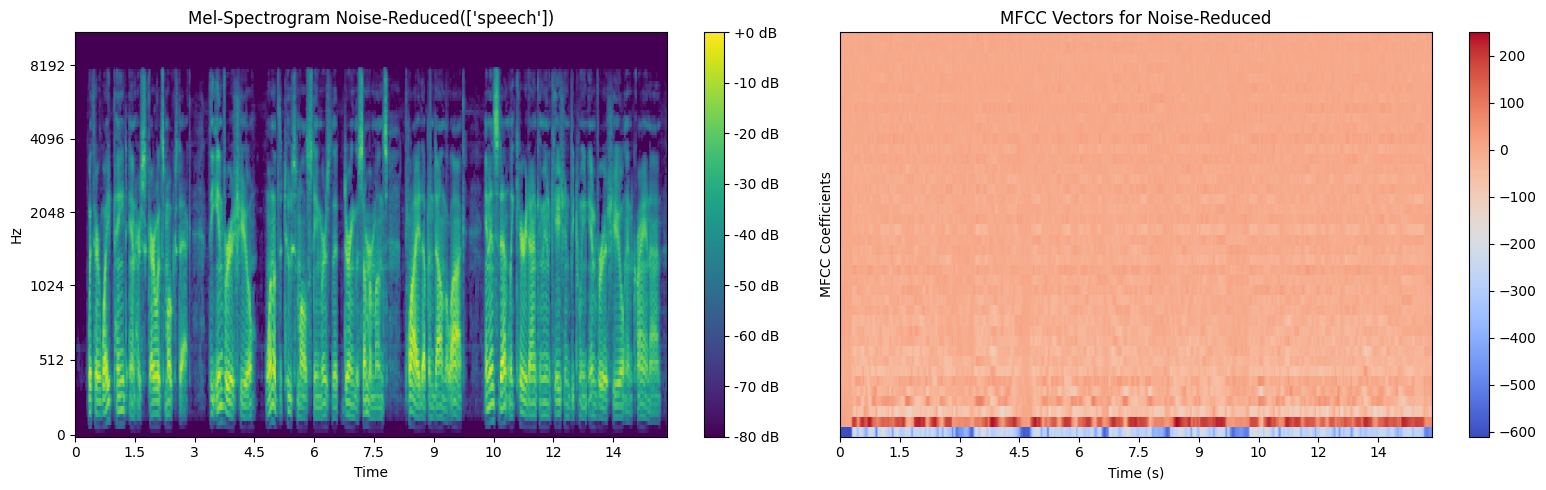

In [50]:
mel_spect_x = librosa.feature.melspectrogram(y=y_clean, sr=sr, n_mels=128)
mel_spect_db_x = librosa.power_to_db(mel_spect_x, ref=np.max)
mfccs_x = librosa.feature.mfcc(y=y_clean, sr=sr, n_mfcc=40)

plt.figure(figsize=(16, 5))

plt.subplot(1, 2, 1)
librosa.display.specshow(mel_spect_db_x, sr=sr, x_axis='time', y_axis='mel', cmap='viridis')
plt.colorbar(format='%+2.0f dB')
plt.title(f'Mel-Spectrogram Noise-Reduced({clip.tags.labels})')

plt.subplot(1, 2, 2)
librosa.display.specshow(mfccs_x, sr=sr, x_axis='time', cmap='coolwarm')
plt.colorbar()
plt.title('MFCC Vectors for Noise-Reduced')
plt.xlabel('Time (s)')
plt.ylabel('MFCC Coefficients')

plt.tight_layout()
plt.show()

Shape check

In [51]:
print(f"Original Waveform shape: {y_clean.shape}")
print(f"Mel-Spectrogram matrix shape: {mel_spect_db_x.shape} (Mels, Frames)")
print(f"MFCC matrix shape: {mfccs_x.shape} (Coefficients, Frames)")

Original Waveform shape: (327222,)
Mel-Spectrogram matrix shape: (128, 640) (Mels, Frames)
MFCC matrix shape: (40, 640) (Coefficients, Frames)


MFCC on clip 2


Sampling Rate: 22050 Hz | Samples: 117601 | dtype: float32
First 20 samples: [-1.407e-03 -4.460e-04 -4.110e-04  1.000e-04  4.300e-05 -1.750e-04
 -3.680e-04  1.460e-04  5.060e-04  1.493e-03  1.856e-03  9.290e-04
 -4.070e-04 -2.039e-03 -1.269e-03 -5.350e-04  8.990e-04  9.760e-04
  1.002e-03 -1.296e-03]


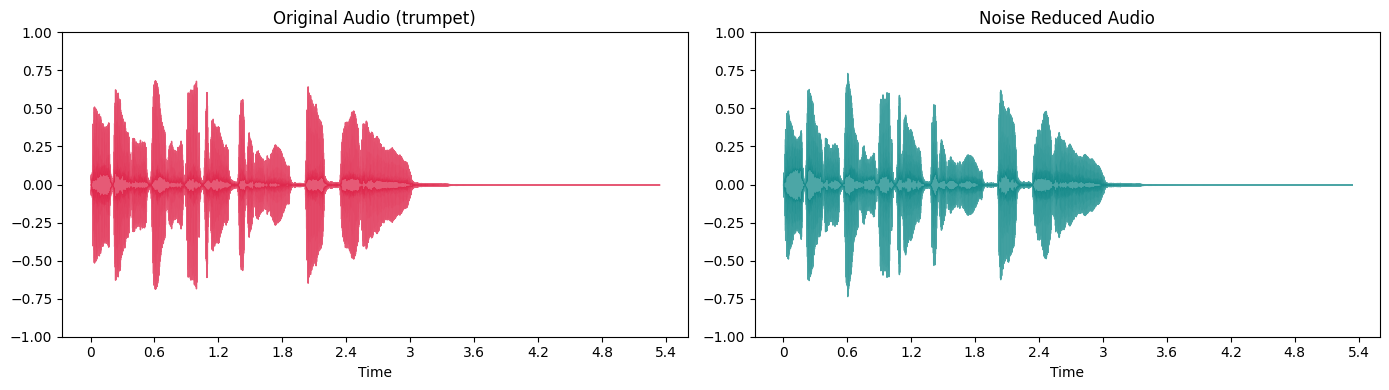

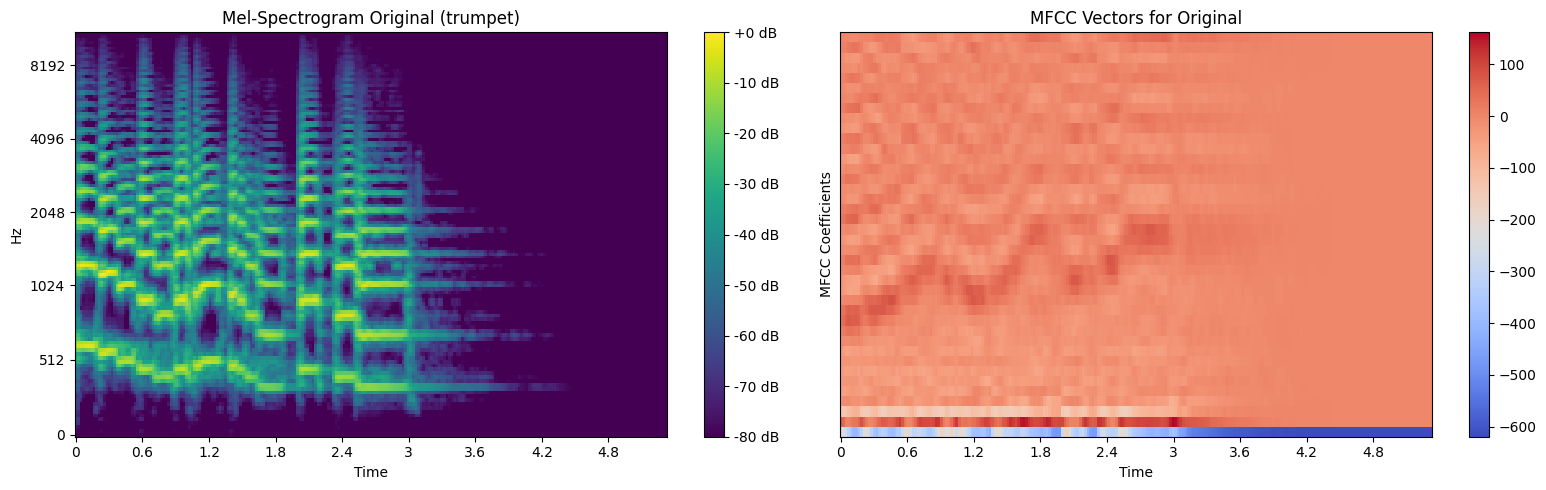

[Original] Mel shape: (128, 230) | MFCC shape: (40, 230)


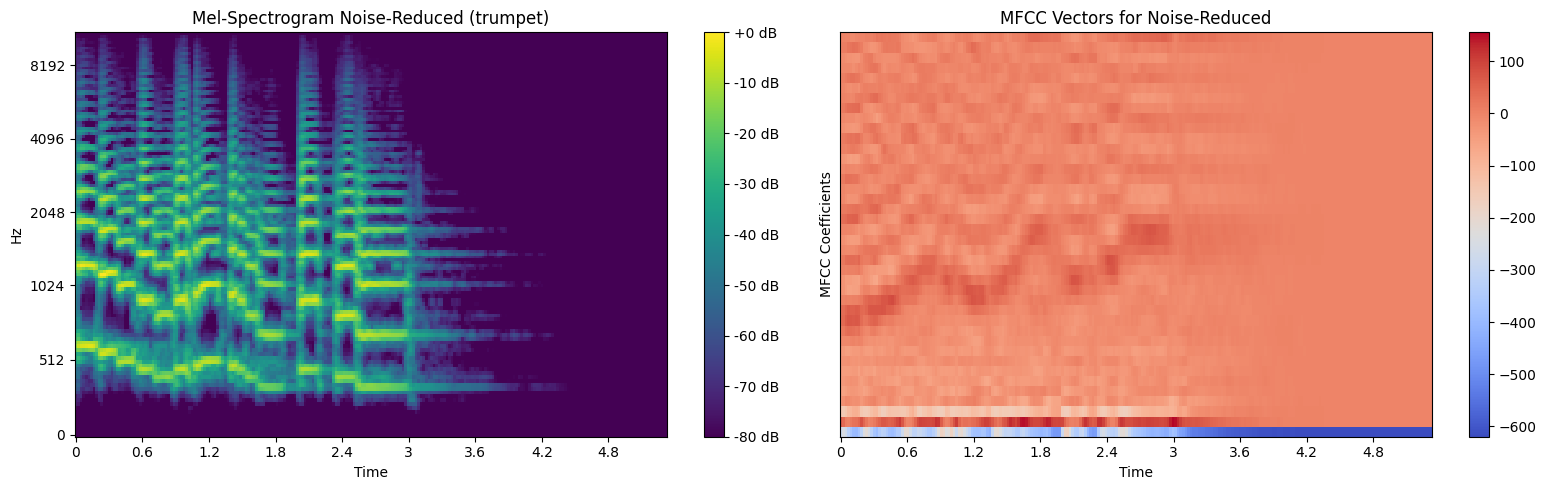

[Noise-Reduced] Mel shape: (128, 230) | MFCC shape: (40, 230)


In [55]:
def analyze_clip(clip_obj):
    y2, sr2 = librosa.load(clip_obj.audio_path, sr=None)
    y2_clean = butter_highpass_filter(y2, cutoff=300, fs=sr2)
    label = clip_obj.tags.labels[0]

    # Metadata
    print(f"Sampling Rate: {sr2} Hz | Samples: {len(y2)} | dtype: {y2.dtype}")
    print("First 20 samples:", np.round(y2[:20], 6))

    # 1) Waveform: original vs cleaned
    plt.figure(figsize=(14, 4))
    plt.subplot(1, 2, 1)
    librosa.display.waveshow(y2, sr=sr2, color='crimson', alpha=0.7)
    plt.title(f'Original Audio ({label})'); plt.ylim(-1, 1)
    plt.subplot(1, 2, 2)
    librosa.display.waveshow(y2_clean, sr=sr2, color='teal', alpha=0.7)
    plt.title('Noise Reduced Audio'); plt.ylim(-1, 1)
    plt.tight_layout(); plt.show()

    # 2) Features: original aur cleaned for both
    for name, sig in [("Original", y2), ("Noise-Reduced", y2_clean)]:
        mel = librosa.power_to_db(
            librosa.feature.melspectrogram(y=sig, sr=sr2, n_mels=128), ref=np.max)
        mf = librosa.feature.mfcc(y=sig, sr=sr2, n_mfcc=40)

        plt.figure(figsize=(16, 5))
        plt.subplot(1, 2, 1)
        librosa.display.specshow(mel, sr=sr2, x_axis='time', y_axis='mel', cmap='viridis')
        plt.colorbar(format='%+2.0f dB'); plt.title(f'Mel-Spectrogram {name} ({label})')
        plt.subplot(1, 2, 2)
        librosa.display.specshow(mf, sr=sr2, x_axis='time', cmap='coolwarm')
        plt.colorbar(); plt.title(f'MFCC Vectors for {name}')
        plt.ylabel('MFCC Coefficients')
        plt.tight_layout(); plt.show()

        print(f"[{name}] Mel shape: {mel.shape} | MFCC shape: {mf.shape}")

    return y2, y2_clean

y2, y2_clean = analyze_clip(clip2)

Created By Areeba Khanam (021011802023) ECEAI 1